TODO: (DO NOT INTERACT OR TRY AND FIX THESE, THESE ARE JUST NOTES FOR MYSELF, START FROM THE IMPORTS)
NOISE TYPES FOR EACH METHOD
MAKE MASK INDICATE NOISE TYPE
EDA (HIST BUT NOISE COLOURED)
END MODEL THAT COMPARES CLEAN TO DIRTY TO CLEANED

READ D3

CHECKS (BLOB COUNT, STD, FEATURE COUNT)
EPS DETERMINER
ASSUMPTIONS

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor
from umap import UMAP

/var/home/loading/Downloads/CODING/venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
rand = 42
sample_amount = 40_000
feature_amount = 20
blob_amount = 8
cluster_std = 1.2

X, _ = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=blob_amount, cluster_std=cluster_std, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [4]:
def inject_noise(df, noise_frac=0.1, n_features_affected=None, seed=rand):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=int)

    for row_id in noise_idx:
        method = rng.integers(low=1, high=5, endpoint=True)
        mask[row_id] = method
        match method:
            case 1:
                cols = cols_all
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(8, 12) * std

            case 2:
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(4, 6) * std

            case 3:
                # KMeans: swap this row's values with another random row's values on the
                # affected columns. Every value stays perfectly in-distribution marginally
                # (it's a real value from a real row), so no single axis looks extreme and
                # Isolation Forest's axis-aligned splits have nothing to grab onto. But the
                # *combination* of features no longer matches any real cluster's correlation
                # structure, so it ends up far from every centroid in full-dimensional space.
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                donor_row = rng.choice(df.index[df.index != row_id])
                for col in cols:
                    std = df[col].std()  # unused here, kept for signature/logging consistency
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 4:
                # DBSCAN: replace values with values drawn uniformly from each column's own
                # min/max range. Like the shuffle case, each individual value is plausible
                # on its own axis, but drawing independently per column (instead of copying
                # a real row) tends to land the point in genuinely low-density gaps between
                # blobs rather than just "a different real cluster's shape" — a better match
                # for a density-based detector than a centroid-distance one.
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                for col in cols:
                    std = df[col].std()  # unused here, kept for signature/logging consistency
                    noisy.loc[row_id, col] = rng.uniform(df[col].min(), df[col].max())

            case 5:
                # LOF: a small, correlated shift — deliberately weaker than cases 2-4 — that
                # nudges the point toward a locally sparser sub-region without pushing it far
                # enough from its own cluster's centroid or density envelope to trip KMeans'
                # percentile cutoff or DBSCAN's global eps. Only a *local* density comparison
                # (LOF's specialty) should pick this up.
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                direction = rng.choice([-1, 1])  # same direction across cols -> coherent local shift
                for col in cols:
                    std = df[col].std()
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(1.5, 2.5) * std

    return noisy, mask

noisy_df, true_mask = inject_noise(df, noise_frac=0.3, n_features_affected=20)

'''
    #1 | extreme       | push feature values far outside range
    #2 | gaussian       | add jitter to feature values
    #3 | shuffle        | swap feature values with other row's
    #4 | uniform_random | replace feature values with values from data range (ignores correlation)

            case 1:
                direction = rng.choice([-1, 1])
                magnitude = rng.uniform(6, 12)
                noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

            case 2:
                noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

            case 3:
                donor_id = rng.choice(df.index)
                noisy.loc[row_id, col] = df.loc[donor_id, col]

            case 4:
                lo, hi = df[col].min(), df[col].max()
                noisy.loc[row_id, col] = rng.uniform(lo, hi)
'''

"\n    #1 | extreme       | push feature values far outside range\n    #2 | gaussian       | add jitter to feature values\n    #3 | shuffle        | swap feature values with other row's\n    #4 | uniform_random | replace feature values with values from data range (ignores correlation)\n\n            case 1:\n                direction = rng.choice([-1, 1])\n                magnitude = rng.uniform(6, 12)\n                noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude\n\n            case 2:\n                noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)\n\n            case 3:\n                donor_id = rng.choice(df.index)\n                noisy.loc[row_id, col] = df.loc[donor_id, col]\n\n            case 4:\n                lo, hi = df[col].min(), df[col].max()\n                noisy.loc[row_id, col] = rng.uniform(lo, hi)\n"

In [5]:
#AMOUNT OF NOISE
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

0.0201


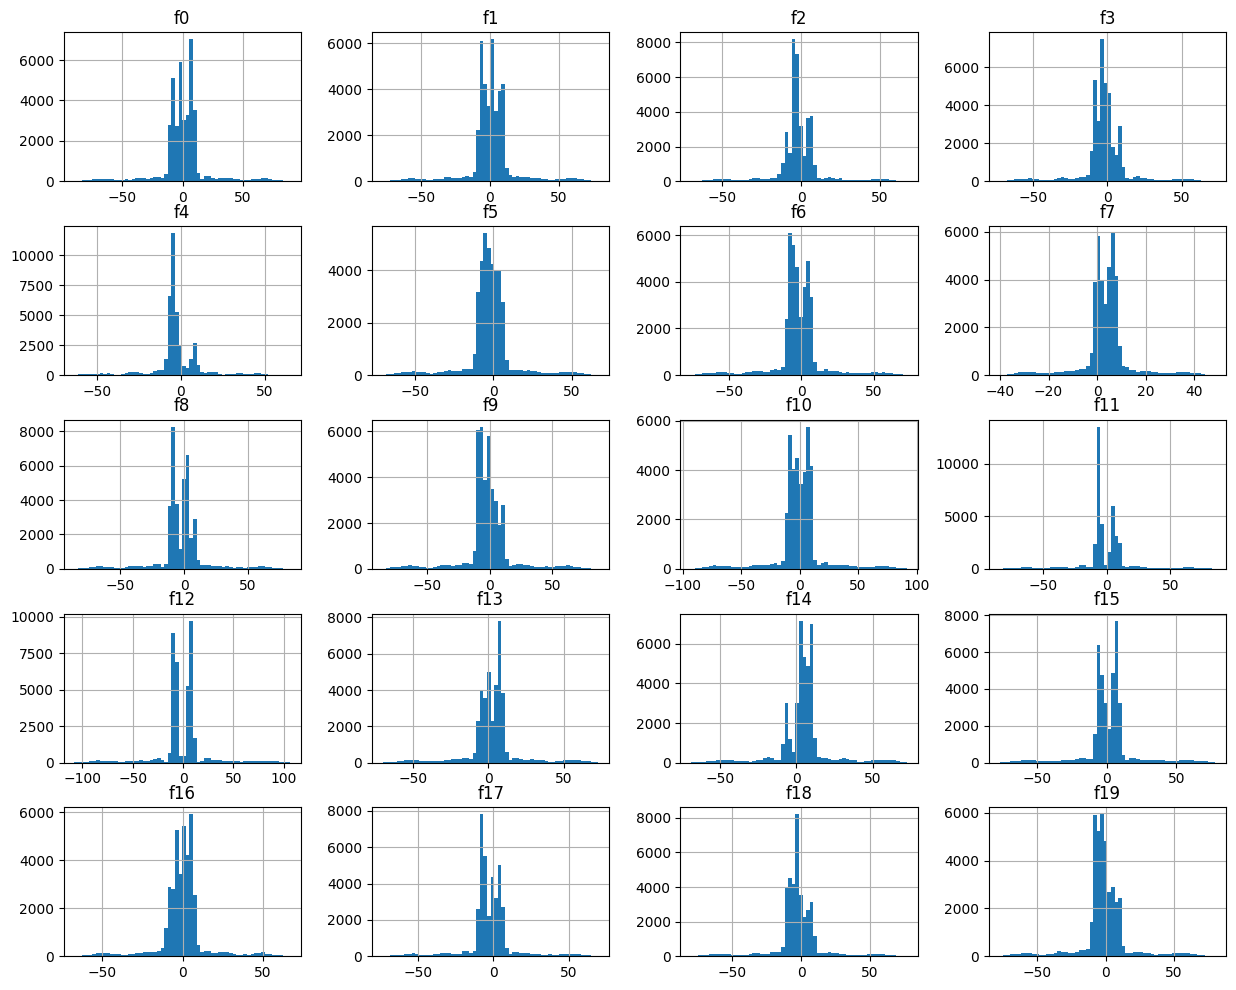

/var/home/loading/Downloads/CODING/venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/var/home/loading/Downloads/CODING/venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


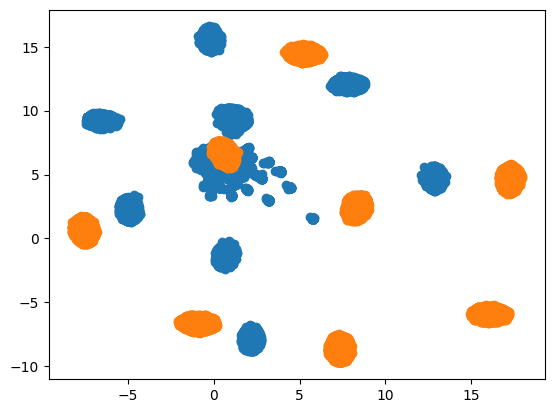

In [13]:
#HIST OF ALL FEATURES
noisy_df.hist(figsize=(15, 12), bins=60)
plt.show()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(noisy_df)
scaler = StandardScaler()
X_scaleddf = scaler.fit_transform(df)
embedding = UMAP(n_components=2, random_state=42, n_neighbors=45, min_dist=0.1).fit_transform(X_scaled)
embedding1 = UMAP(n_components=2, random_state=42, n_neighbors=45, min_dist=0.1).fit_transform(X_scaleddf)
plt.scatter(embedding[:, 0],
    embedding[:, 1])
plt.scatter(embedding1[:, 0],
    embedding1[:, 1])

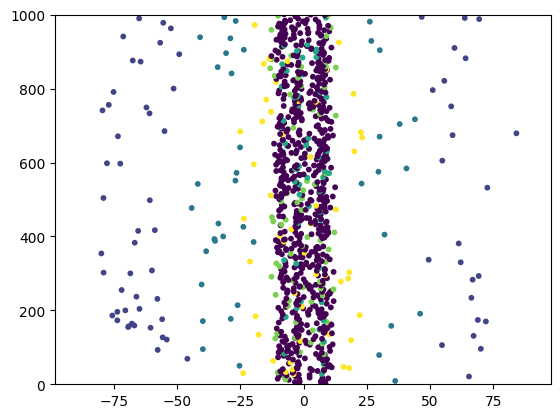

In [12]:
#PLOT FIRST FEATURE
plt.scatter(noisy_df.iloc[:, 0], df.index, c=true_mask, s=10)
plt.scatter
plt.ylim(0, 1000)
plt.show()

In [38]:
def confusion_custom(mask, flagged):
    fp = iqr = isfo = kmeans = dbscan = lof = 0
    for i in range(len(mask)):
        if flagged[i] == True:
            match mask[i]:
                case 0:
                    fp += 1
                case 1:
                    iqr += 1
                case 2:
                    isfo += 1
                case 3:
                    kmeans += 1
                case 4:
                    dbscan += 1
                case 5:
                    lof += 1
    print(f"false positives: {fp}")
    print(f"true positives: {iqr + isfo + kmeans + dbscan + lof}\n")
    print(f"noise 1 detected {iqr}")
    print(f"noise 2 detected {isfo}")
    print(f"noise 3 detected {kmeans}")
    print(f"noise 4 detected {dbscan}")
    print(f"noise 5 detected {lof}")


def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None):
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    print(f"IQR: ")
    if mask is not None:
        confusion_custom(mask, flagged)
        print(classification_report(mask == 0, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0)) ############
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_isolation_forest(data, isof_estimators, mask=None):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    print(f"ISOLATION FOREST: ")
    if mask is not None:
        confusion_custom(mask, flagged)
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None):
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(X)
            silhouette = silhouette_score(X, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    print(f"K MEANS: ")
    if mask is not None:
        confusion_custom(mask, flagged)
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    print(f"DBSCAN: ")
    if mask is not None:
        confusion_custom(mask, flagged)
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_lof(data, lof_neighbors, mask=None):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    print(f"LOF: ")
    if mask is not None:
        confusion_custom(mask, flagged)
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

In [39]:
def pipeline(data, mask=None, clusters=None):
    #hyperparam
    iqr_fence = 1.5
    iqr_col_ratio = 0.8
    isof_estimators = 480 
    kmeans_init = 20
    kmeans_contam = 0.02
    dbscan_eps = 3
    dbscan_min_samp = 40
    lof_neighbors = 20

    if mask is None:
        data = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio)
        data = run_isolation_forest(data=data, isof_estimators=isof_estimators)
        data = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam)
        data = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp)
        data = run_lof(data=data, lof_neighbors=lof_neighbors)
    else:
        data, mask = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, mask=mask)
        data, mask = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask)
        data, mask = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask)
        data, mask = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask)
        data, mask = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask)

IQR: 
false positives: 0
true positives: 3180

noise 1 detected 2396
noise 2 detected 784
noise 3 detected 0
noise 4 detected 0
noise 5 detected 0
              precision    recall  f1-score   support

      Normal       0.24      0.73      0.36     12000
     Outlier       0.00      0.00      0.00     28000

    accuracy                           0.22     40000
   macro avg       0.12      0.37      0.18     40000
weighted avg       0.07      0.22      0.11     40000

entries remaining: 36820
entries flagged: 3180
ISOLATION FOREST: 
false positives: 0
true positives: 3986

noise 1 detected 0
noise 2 detected 1575
noise 3 detected 0
noise 4 detected 0
noise 5 detected 2411
              precision    recall  f1-score   support

      Normal       0.85      1.00      0.92     28000
     Outlier       0.00      0.00      0.00         0

   micro avg       0.76      1.00      0.86     28000
   macro avg       0.43      0.50      0.46     28000
weighted avg       0.85      1.00      0.92   

/var/home/loading/Downloads/CODING/venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/var/home/loading/Downloads/CODING/venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


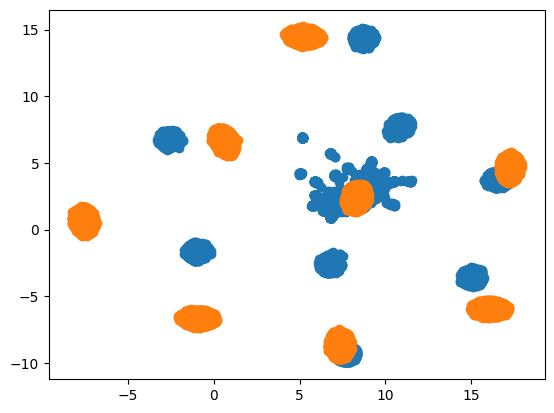

In [41]:
data = noisy_df.copy()
mask = true_mask.copy()
pipeline(data, mask=mask, clusters=8)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)
embedding = UMAP(n_components=2, random_state=42, n_neighbors=45, min_dist=0.1).fit_transform(data)
plt.scatter(embedding[:, 0],
    embedding[:, 1])

scaler = StandardScaler()
X_scaleddf = scaler.fit_transform(df)
embedding1 = UMAP(n_components=2, random_state=42, n_neighbors=45, min_dist=0.1).fit_transform(X_scaleddf)
plt.scatter(embedding1[:, 0],
    embedding1[:, 1])

In [ ]:

from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

